In [176]:
seed = 42
eval_steps = 10

In [177]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import ConfusionMatrixDisplay

In [178]:
print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [179]:
tf.keras.utils.set_random_seed(seed)

model = Sequential([
    Input(shape=(29,)),
    Dense(64, activation='tanh'),
    Dense(32, activation='tanh'),
    Dense(16, activation='tanh'),
    Dense(8, activation='tanh'),
    Dense(4, activation='tanh'),
    Dense(2, activation='tanh'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'f1_score', 'recall', 'precision']
)

In [180]:
data = pd.read_csv('data/creditcard_2023_processed.csv')
columns = data.select_dtypes(include=['float64']).columns
data[columns] = MinMaxScaler().fit_transform(data[columns])
data

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.565091,0.911068,0.328143,0.597037,0.191428,0.462018,0.021919,0.635760,0.186457,0.108955,...,0.701574,0.390449,0.486438,0.248563,0.486606,0.562599,0.084195,0.334369,0.747484,0
1,0.782703,0.913159,0.216170,0.554606,0.194228,0.455582,0.021412,0.635574,0.170651,0.105862,...,0.698503,0.350024,0.489894,0.204923,0.488866,0.615402,0.082847,0.335113,0.270170,0
2,0.565157,0.902238,0.283790,0.551131,0.190372,0.476540,0.022929,0.637820,0.145310,0.110474,...,0.705416,0.414277,0.503854,0.171033,0.460686,0.571403,0.082425,0.333564,0.102690,0
3,0.584043,0.910345,0.284848,0.473588,0.193703,0.470699,0.021915,0.639641,0.147624,0.107164,...,0.700250,0.377889,0.485160,0.127679,0.517692,0.556742,0.083515,0.336085,0.222361,0
4,0.574494,0.916671,0.272150,0.552320,0.190981,0.457739,0.022548,0.630815,0.199894,0.118424,...,0.701704,0.415594,0.486005,0.257170,0.467467,0.671330,0.085043,0.339272,0.593122,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
568625,0.465034,0.920852,0.131948,0.718217,0.169934,0.456700,0.017916,0.654887,0.117133,0.057371,...,0.711697,0.400373,0.509389,0.185933,0.501991,0.593560,0.111595,0.336370,0.181082,1
568626,0.493503,0.915978,0.179994,0.574517,0.186428,0.451533,0.019507,0.634699,0.176331,0.084632,...,0.706759,0.398823,0.486124,0.189127,0.476699,0.735609,0.072497,0.350324,0.191889,1
568627,0.556121,0.919638,0.191875,0.602904,0.188163,0.449078,0.019264,0.642342,0.151106,0.086533,...,0.710724,0.406108,0.485207,0.212466,0.501262,0.539422,0.080911,0.333357,0.980530,1
568628,0.721873,0.910197,0.166548,0.589585,0.191454,0.440296,0.022196,0.631110,0.193383,0.088379,...,0.703401,0.370161,0.485782,0.206258,0.478604,0.490391,0.083564,0.335012,0.421461,1


In [181]:
x_data = data.drop(columns=['Class'])
y_data = data['Class']

x_train, x_test, y_train, y_test = train_test_split(
    x_data,
    y_data,
    test_size=0.15,
    random_state=seed,
    stratify=y_data
)

In [182]:
model.fit(
    x_train,
    y_train,
    epochs=25,
    batch_size=2048,
    validation_split=0.1
)
model.evaluate(x_test, y_test, return_dict=True)

Epoch 1/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9365 - f1_score: 0.6666 - loss: 0.3110 - precision: 0.9666 - recall: 0.9043 - val_accuracy: 0.9559 - val_f1_score: 0.6672 - val_loss: 0.2243 - val_precision: 0.9730 - val_recall: 0.9380
Epoch 2/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9569 - f1_score: 0.6666 - loss: 0.2016 - precision: 0.9724 - recall: 0.9405 - val_accuracy: 0.9605 - val_f1_score: 0.6672 - val_loss: 0.1785 - val_precision: 0.9701 - val_recall: 0.9504
Epoch 3/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9603 - f1_score: 0.6666 - loss: 0.1679 - precision: 0.9742 - recall: 0.9458 - val_accuracy: 0.9616 - val_f1_score: 0.6672 - val_loss: 0.1554 - val_precision: 0.9640 - val_recall: 0.9593
Epoch 4/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9620 - f1_score: 0.6666 - loss: 0.1478 - precision: 0.9749 - recall: 0.9485 - val_accuracy: 0.9633 - val_f1_score: 0.6672 - val_loss: 0.1375 - val_precision: 0.9731 - val_recall:

{'accuracy': 0.9731285572052002,
 'f1_score': 0.6666613817214966,
 'loss': 0.07223748415708542,
 'precision': 0.9658316969871521,
 'recall': 0.980959951877594}

In [183]:
test_metrics = model.evaluate(x_test, y_test, return_dict=True, verbose=0)
for metric_name, metric_value in test_metrics.items():
    print(f'Test {metric_name}: {metric_value:.4f}')

Test accuracy: 0.9731
Test f1_score: 0.6667
Test loss: 0.0722
Test precision: 0.9658
Test recall: 0.9810


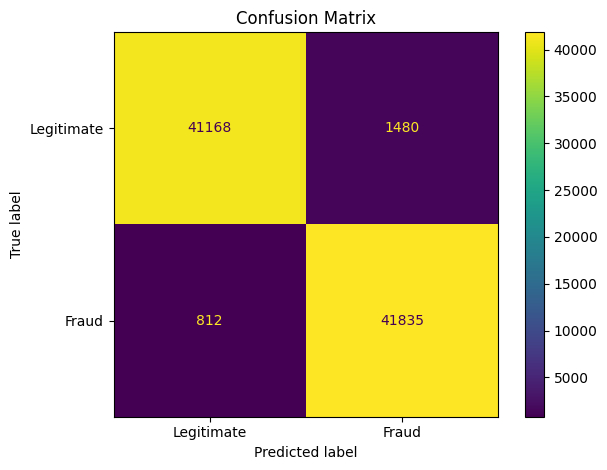

In [184]:
y_prob = model.predict(x_test, verbose=0).ravel()
# Convert predicted probabilities to binary class predictions
y_pred = (y_prob >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Legitimate', 'Fraud']
)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()